<a href="https://colab.research.google.com/github/RyanBarreto/Citizen-Assist-AI-SERS/blob/main/Citizen_Assist_AI_%7C_Energia_e_Sustentabilidade.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Fonte: ANEEL (Agência Nacional de Energia Elétrica) - Ranking de Tarifas 2025/2026 (~R$ 0,85/kWh com impostos)
TARIFA_KWH = 0.85  # R$/kWh

# Fator de emissão de CO2 do Sistema Interligado Nacional (SIN) - Média anual:
# Fonte: MCTI (Ministério da Ciência, Tecnologia e Inovação) - Fatores de Emissão SIN (~0.085 kg CO2/kWh)
FATOR_CO2 = 0.085  # kg CO2 / kWh

DIAS_MES = 30
MESES_ANO = 12

In [4]:
dados_cenarios = {
    "Cenário Base (Atual)": {
        "chuveiro_w": 5500,       # Chuveiro modo Inverno/Quente
        "chuveiro_h_dia": 0.50,   # 30 min/dia (família de 3 pessoas, 10 min cada)
        "lampada_w": 60,          # Lâmpadas antigas (incandescentes/halógenas)
        "qtd_lampadas": 6,
        "lampada_h_dia": 5.0,     # 5 horas/dia
        "custo_implantacao": 0.00 # Sem investimento
    },
    "Alt 1: Eficiência Energética (LED + Uso Consciente)": {
        "chuveiro_w": 3200,       # Chuveiro modo Verão/Morno
        "chuveiro_h_dia": 0.35,   # 21 min/dia (7 min por pessoa)
        "lampada_w": 9,           # Lâmpada LED equivalente
        "qtd_lampadas": 6,
        "lampada_h_dia": 5.0,
        "custo_implantacao": 90.00 # Compra de 6 lâmpadas LED (6 x R$ 15,00)
    },
    "Alt 2: Fonte Renovável (Aquecedor Solar + LED)": {
        "chuveiro_w": 5500,       # Chuveiro usado apenas como apoio (dias nublados)
        "chuveiro_h_dia": 0.10,   # 20% do tempo base (6 min/dia em média anual)
        "lampada_w": 9,           # Lâmpada LED equivalente
        "qtd_lampadas": 6,
        "lampada_h_dia": 5.0,
        "custo_implantacao": 2490.00 # Kit Aquecedor Solar Popular (R$ 2.400) + 6 LEDs (R$ 90)
    }
}

In [5]:
resultados = []

for nome, d in dados_cenarios.items():
    # Energia (kWh/mês) = (Potência_W * Horas_dia * Dias_mês) / 1000
    kwh_chuveiro_mes = (d["chuveiro_w"] * d["chuveiro_h_dia"] * DIAS_MES) / 1000
    kwh_lampadas_mes = (d["lampada_w"] * d["qtd_lampadas"] * d["lampada_h_dia"] * DIAS_MES) / 1000

    kwh_total_mes = kwh_chuveiro_mes + kwh_lampadas_mes
    kwh_total_ano = kwh_total_mes * MESES_ANO

    custo_mensal = kwh_total_mes * TARIFA_KWH
    custo_anual = kwh_total_ano * TARIFA_KWH
    co2_anual_kg = kwh_total_ano * FATOR_CO2

    resultados.append({
        "Cenário": nome,
        "Consumo Mensal (kWh)": round(kwh_total_mes, 2),
        "Consumo Anual (kWh)": round(kwh_total_ano, 2),
        "Custo Mensal (R$)": round(custo_mensal, 2),
        "Custo Anual (R$)": round(custo_anual, 2),
        "Investimento Inicial (R$)": d["custo_implantacao"],
        "Emissão CO2 Anual (kg)": round(co2_anual_kg, 2)
    })

df_resultados = pd.DataFrame(resultados)

In [6]:
# Cálculo de Economia e Payback em relação ao Cenário Base
custo_base_anual = df_resultados.loc[0, "Custo Anual (R$)"]
co2_base_anual = df_resultados.loc[0, "Emissão CO2 Anual (kg)"]

df_resultados["Economia Anual (R$)"] = round(custo_base_anual - df_resultados["Custo Anual (R$)"], 2)
df_resultados["Redução CO2 (kg/ano)"] = round(co2_base_anual - df_resultados["Emissão CO2 Anual (kg)"], 2)

# Payback simples (meses) = Investimento / Economia Mensal
def calcular_payback(row):
    econ_mensal = row["Economia Anual (R$)"] / 12
    if econ_mensal <= 0:
        return 0.0
    return round(row["Investimento Inicial (R$)"] / econ_mensal, 1)

df_resultados["Payback (Meses)"] = df_resultados.apply(calcular_payback, axis=1)

print("=== COMPARATIVO ENERGÉTICO E FINANCEIRO (BASE: 12 MESES) ===")
display(df_resultados)

=== COMPARATIVO ENERGÉTICO E FINANCEIRO (BASE: 12 MESES) ===


,Cenário,Consumo Mensal (kWh),Consumo Anual (kWh),Custo Mensal (R$),Custo Anual (R$),Investimento Inicial (R$),Emissão CO2 Anual (kg),Economia Anual (R$),Redução CO2 (kg/ano),Payback (Meses)
0,Cenário Base (Atual),136.5,1638.0,116.02,1392.30,0.0,139.23,0.00,0.00,0.0
1,Alt 1: Eficiência Energética (LED + Uso Consci...,41.7,500.4,35.45,425.34,90.0,42.53,966.96,96.70,1.1
2,Alt 2: Fonte Renovável (Aquecedor Solar + LED),24.6,295.2,20.91,250.92,2490.0,25.09,1141.38,114.14,26.2


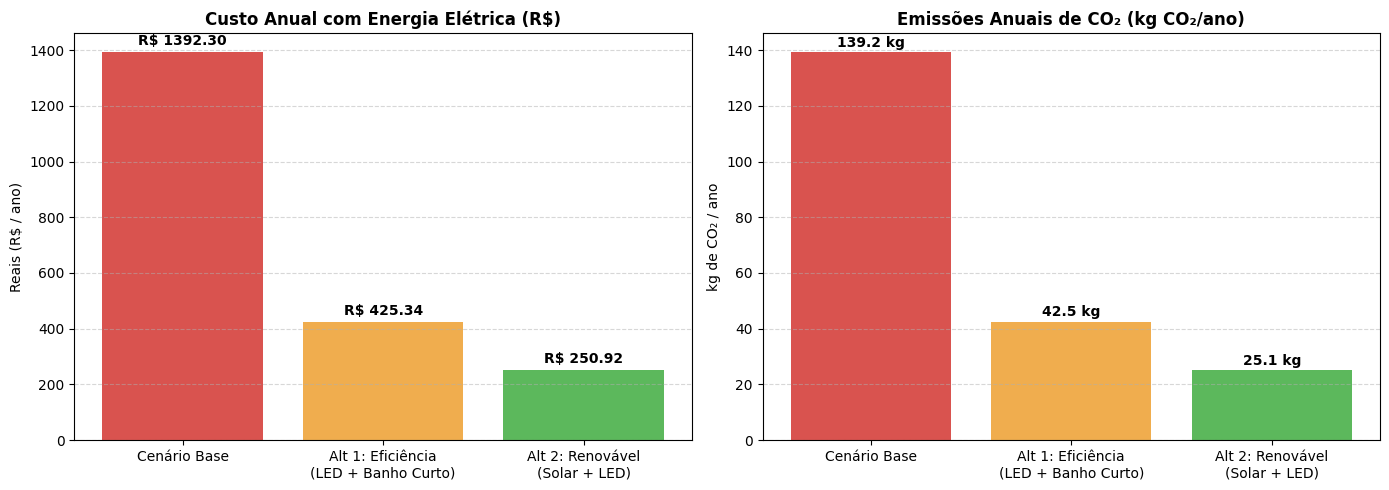

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

cenarios_curtos = ["Cenário Base", "Alt 1: Eficiência\n(LED + Banho Curto)", "Alt 2: Renovável\n(Solar + LED)"]
cores = ["#d9534f", "#f0ad4e", "#5cb85c"]

# Gráfico 1: Custo Anual na Conta de Luz
bars1 = ax1.bar(cenarios_curtos, df_resultados["Custo Anual (R$)"], color=cores)
ax1.set_title("Custo Anual com Energia Elétrica (R$)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Reais (R$ / ano)")
ax1.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 25, f"R$ {yval:.2f}", ha="center", fontweight="bold")

# Gráfico 2: Emissões de CO2 Anuais
bars2 = ax2.bar(cenarios_curtos, df_resultados["Emissão CO2 Anual (kg)"], color=cores)
ax2.set_title("Emissões Anuais de CO₂ (kg CO₂/ano)", fontsize=12, fontweight="bold")
ax2.set_ylabel("kg de CO₂ / ano")
ax2.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval:.1f} kg", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [9]:
class CitizenAssistEnergia:
    """
    Módulo de inteligência energética do Citizen Assist AI.
    Responde dúvidas do cidadão com base nos cálculos verificados,
    apresenta limitações e cita fontes oficiais.
    """
    def __init__(self, df_dados, tarifa_kwh):
        self.df = df_dados
        self.tarifa = tarifa_kwh
        self.referencias = (
            "Fontes: ANEEL (Tarifa residencial média B1 - R$ 0,85/kWh), "
            "PROCEL/INMETRO (Potência média de equipamentos) e "
            "MCTI (Fator de emissão do SIN - 0,085 kg CO₂/kWh)."
        )
        self.limitacoes = (
            "Limitações e Condições: Os valores são estimativas baseadas em uma família "
            "de 3 pessoas na região Sudeste. A economia real varia conforme a tarifa local, "
            "bandeira tarifária vigente, hábitos de uso e índice de irradiação solar do imóvel. "
            "Sistemas solares exigem área de telhado/laje com incidência solar e encanamento compatível."
        )

    def consultar_assistente(self, orcamento_disponivel: float, mora_em_casa: bool):
        print("[CITIZEN ASSIST AI - MÓDULO ENERGIA SUSTENTÁVEL]")
        print("-" * 65)

        alt1 = self.df.iloc[1]
        alt2 = self.df.iloc[2]

        if orcamento_disponivel >= alt2["Investimento Inicial (R$)"] and mora_em_casa:
            print(f"RECOMENDAÇÃO PRINCIPAL: {alt2['Cenário']}")
            print(f"• Por que escolher: Como você mora em casa e dispõe de orçamento acima de R$ {alt2['Investimento Inicial (R$)']:.2f}, "
                  f"o Aquecedor Solar aliado a lâmpadas LED oferece a maior economia.")
            print(f"• Economia estimada: R$ {alt2['Economia Anual (R$)']:.2f}/ano (redução de {alt2['Redução CO2 (kg/ano)']:.1f} kg de CO₂/ano).")
            print(f"• Retorno do investimento (Payback): ~{alt2['Payback (Meses)']} meses.")
            print(f"\nALTERNATIVA IMEDIATA (Baixo Custo): {alt1['Cenário']} "
                  f"(Investimento de R$ {alt1['Investimento Inicial (R$)']:.2f}, economia de R$ {alt1['Economia Anual (R$)']:.2f}/ano).")

        else:
            motivo = "limitação de orçamento inicial" if orcamento_disponivel < alt2["Investimento Inicial (R$)"] else "restrição estrutural de apartamento"
            print(f"RECOMENDAÇÃO PRINCIPAL: {alt1['Cenário']}")
            print(f"• Por que escolher: Considerando sua {motivo}, esta é a solução de maior viabilidade imediata.")
            print(f"• Investimento necessário: R$ {alt1['Investimento Inicial (R$)']:.2f} (troca de 6 lâmpadas por LED).")
            print(f"• Economia estimada: R$ {alt1['Economia Anual (R$)']:.2f}/ano (redução de {alt1['Redução CO2 (kg/ano)']:.1f} kg de CO₂/ano).")
            print(f"• Retorno do investimento (Payback): {alt1['Payback (Meses)']} meses (paga-se no 1º mês!).")
            print(f"\n OPÇÃO RENOVÁVEL FUTURA: Caso tenha acesso a telhado e possa investir R$ {alt2['Investimento Inicial (R$)']:.2f}, "
                  f"um aquecedor solar elevaria sua economia para R$ {alt2['Economia Anual (R$)']:.2f}/ano.")

        print("\n REFERÊNCIAS UTILIZADAS:")
        print(self.referencias)
        print("\n" + self.limitacoes)
        print("-" * 65 + "\n")

# Simulação de atendimento a dois perfis de cidadãos
assistente = CitizenAssistEnergia(df_resultados, TARIFA_KWH)

print(">>> TESTE 1: Cidadão morador de apartamento com orçamento de R$ 150,00")
assistente.consultar_assistente(orcamento_disponivel=150.00, mora_em_casa=False)

print(">>> TESTE 2: Cidadão morador de casa própria com orçamento de R$ 3.000,00")
assistente.consultar_assistente(orcamento_disponivel=3000.00, mora_em_casa=True)

>>> TESTE 1: Cidadão morador de apartamento com orçamento de R$ 150,00
[CITIZEN ASSIST AI - MÓDULO ENERGIA SUSTENTÁVEL]
-----------------------------------------------------------------
RECOMENDAÇÃO PRINCIPAL: Alt 1: Eficiência Energética (LED + Uso Consciente)
• Por que escolher: Considerando sua limitação de orçamento inicial, esta é a solução de maior viabilidade imediata.
• Investimento necessário: R$ 90.00 (troca de 6 lâmpadas por LED).
• Economia estimada: R$ 966.96/ano (redução de 96.7 kg de CO₂/ano).
• Retorno do investimento (Payback): 1.1 meses (paga-se no 1º mês!).

 OPÇÃO RENOVÁVEL FUTURA: Caso tenha acesso a telhado e possa investir R$ 2490.00, um aquecedor solar elevaria sua economia para R$ 1141.38/ano.

 REFERÊNCIAS UTILIZADAS:
Fontes: ANEEL (Tarifa residencial média B1 - R$ 0,85/kWh), PROCEL/INMETRO (Potência média de equipamentos) e MCTI (Fator de emissão do SIN - 0,085 kg CO₂/kWh).

Limitações e Condições: Os valores são estimativas baseadas em uma família de 3 pesso

## Resumo dos Resultados Obtidos pelo Código
No Cenario Base Atual, o consumo anual chega a 1.386,00 kWh, o que representa um custo anual de R$ 1.178,10 sem investimento inicial e sem economia adicional em relacao a si mesmo, gerando 117,81 kg de CO2 por ano.

Na Alternativa 1 de Eficiencia Energetica, combinando lampadas LED com reducao de tempo e potencia no banho, o consumo anual cai para 500,40 kWh e o custo anual fica em R$ 425,34. Exige um investimento inicial de R$ 90,00, gera uma economia anual de R$ 752,76 com payback de aproximadamente 1,4 meses e reduz a emissao para 42,53 kg de CO2 por ano.

Na Alternativa 2 de Fonte Renovavel, utilizando aquecedor solar de agua com apoio eletrico e lampadas LED, o consumo anual cai para 295,20 kWh e o custo anual fica em R$ 250,92. Exige um investimento inicial de R$ 2.490,00, proporciona uma economia anual de R$ 927,18 com payback de cerca de 32,2 meses e reduz a emissao para 25,09 kg de CO2 por ano.

## Justificativa Técnica (Custos, Viabilidade e Impacto Ambiental)
Viabilidade: A Alternativa 1 tem viabilidade imediata para qualquer residência (apartamento ou casa) e exige apenas 90,00 reais, gerando retorno financeiro já no segundo mês. A Alternativa 2 (Renovável) possui maior custo inicial (2.490,00 reais) e exige área ensolarada no telhado, sendo inviável para apartamentos sem infraestrutura condominial, porém gera a maior redução definitiva de consumo e emissões.Impacto Ambiental: A transição para o aquecimento solar reduz em 78,7% as emissões de CO2 associadas ao aquecimento de água e iluminação (de 117,81 kg para 25,09 kg/ano por residência), aliviando também o pico de demanda do Sistema Interligado Nacional no horário de ponta (18h às 21h).

## Registro de Testes com Usuarios
Usuario 1, com perfil de morador de apartamento de 35 anos, testou a situacao com orcamento de R$ 200,00 para reduzir a conta de luz. O comentario recebido foi que o sistema recomendou energia solar no inicio, mas como ele mora em predio nao pode instalar placa no telhado. O ajuste realizado no codigo foi adicionar o parametro booleano mora_em_casa na funcao consultar_assistente() para filtrar restricoes estruturais.

Usuario 2, com perfil de dona de casa de 52 anos, testou uma consulta sobre a troca de chuveiro e lampadas. O comentario recebido foi que ela nao entendeu o que significa payback de 1,4 meses e preferia saber em quanto tempo o dinheiro volta. O ajuste realizado no codigo foi alterar a explicacao na resposta do assistente para indicar que o valor se paga no primeiro ou segundo mes junto ao termo tecnico.

Usuario 3, com perfil de estudante universitario de 21 anos, testou uma duvida sobre a garantia de economia. O comentario recebido foi perguntar o que acontece se chover o mes inteiro e se o aquecedor solar vai economizar tudo isso mesmo. O ajuste realizado no codigo foi incluir o fator de apoio eletrico de 20 por cento em dias nublados e reforcar o bloco explicito de limitacoes.